# 06 · The Hong–Ou–Mandel Effect

**Covers:** two-photon interference at a beam splitter, the HOM dip, distinguishability, the dip vs delay curve, and the effect of an unbalanced splitter.
**Photonics thread:** HOM is the standard test of whether two photons are identical. It qualifies single-photon sources and photonic chips, and it sits at the core of linear-optical quantum gates.

In [1]:
import numpy as np
import qutip as qt

results = []   # every theory-vs-simulation check is recorded here

def check(label, sim, theory, tol=1e-3):
    """Compare a simulated number with its analytic value and record the result."""
    sim, theory = float(np.real(sim)), float(np.real(theory))
    ok = bool(np.isclose(sim, theory, atol=tol))
    results.append(ok)
    print(f"{'PASS' if ok else 'FAIL'}  {label}: simulation = {sim:.4f}, theory = {theory:.4f}")

## 1. Two photons at a 50:50 splitter

**Plain words:** send one photon into each input. A coincidence (one photon in each output) can happen two ways: both transmitted, amplitude −½, or both reflected, amplitude +½. The two histories cancel:

$$a^\dagger b^\dagger|0\rangle \;\to\; \tfrac12(a^\dagger + b^\dagger)(a^\dagger - b^\dagger)|0\rangle = \frac{|2,0\rangle - |0,2\rangle}{\sqrt2}$$

Both photons always leave together. Distinguishable particles would give coincidences half the time.

**Gap:** the photons do not attract each other. It is pure amplitude cancellation, and it needs only that nothing can tell the two histories apart.

**One sentence:** identical photons leave a 50:50 splitter together because "both pass" and "both reflect" cancel.

In [2]:
N = 3
a = qt.tensor(qt.destroy(N), qt.qeye(N))
b = qt.tensor(qt.qeye(N), qt.destroy(N))
vac = qt.tensor(qt.basis(N, 0), qt.basis(N, 0))
inp = a.dag() * b.dag() * vac                              # |1,1>

def bs(theta):                                             # theta = pi/4: 50:50
    return (theta * (a.dag() * b - a * b.dag())).expm()

def ket(n1, n2):
    return qt.tensor(qt.basis(N, n1), qt.basis(N, n2))

out = bs(np.pi / 4) * inp
check("P(2,0)", abs(ket(2, 0).dag() * out) ** 2, 0.5)
check("P(1,1): the HOM dip", abs(ket(1, 1).dag() * out) ** 2, 0.0)
check("P(0,2)", abs(ket(0, 2).dag() * out) ** 2, 0.5)
amp20 = (ket(2, 0).dag() * out).real
amp02 = (ket(0, 2).dag() * out).real
print(f"amplitudes: |2,0> {amp20:+.3f}, |0,2> {amp02:+.3f} (opposite signs)")

PASS  P(2,0): simulation = 0.5000, theory = 0.5000
PASS  P(1,1): the HOM dip: simulation = 0.0000, theory = 0.0000
PASS  P(0,2): simulation = 0.5000, theory = 0.5000
amplitudes: |2,0> +0.707, |0,2> -0.707 (opposite signs)


## 2. An unbalanced splitter puts a floor under the dip

With transmission $T$ and reflection $R = 1 - T$ the two histories have sizes $T$ and $R$, so they only cancel when $T = R$:

$$P(1,1) = (T - R)^2 = \cos^2(2\theta)$$

**Photonics:** a directional coupler or MMI that drifts from 50:50 (fabrication, wavelength, temperature) limits HOM visibility even with perfect photons. A 70:30 coupler gives at best 0.16.

**One sentence:** only a balanced splitter makes the dip reach zero.

In [3]:
for theta in [0, np.pi / 8, np.pi / 4]:
    check(f"P(1,1) at theta = {theta:.3f}", abs(ket(1, 1).dag() * bs(theta) * inp) ** 2, np.cos(2 * theta) ** 2)
theta_7030 = np.arccos(np.sqrt(0.7))
check("70:30 coupler floor", abs(ket(1, 1).dag() * bs(theta_7030) * inp) ** 2, (0.7 - 0.3) ** 2)

PASS  P(1,1) at theta = 0.000: simulation = 1.0000, theory = 1.0000
PASS  P(1,1) at theta = 0.393: simulation = 0.5000, theory = 0.5000
PASS  P(1,1) at theta = 0.785: simulation = 0.0000, theory = 0.0000
PASS  70:30 coupler floor: simulation = 0.1600, theory = 0.1600


## 3. Distinguishability kills the dip

**Plain words:** if photon 2 carries any label (colour, arrival time, polarization) the two histories become different events, and different events don't cancel:

$$P_{\text{coinc}} = \tfrac12\left(1 - |\langle\psi_1|\psi_2\rangle|^2\right)$$

Model: photon 2 is $\cos\varphi\,|H\rangle + \sin\varphi\,|V\rangle$, so the overlap is $\cos\varphi$. Here V stands for "whatever part of photon 2's wavepacket does not overlap photon 1".

**One sentence:** the dip is only as deep as the photons are identical.

In [4]:
def op(k):
    ops = [qt.qeye(N)] * 4
    ops[k] = qt.destroy(N)
    return qt.tensor(ops)

aH, aV, bH, bV = [op(k) for k in range(4)]
vac4 = qt.tensor([qt.basis(N, 0)] * 4)
G = (aH.dag() * bH - aH * bH.dag()) + (aV.dag() * bV - aV * bV.dag())
U4 = (np.pi / 4 * G).expm()
Na = aH.dag() * aH + aV.dag() * aV
Nb = bH.dag() * bH + bV.dag() * bV

def coinc(phi):
    inp4 = aH.dag() * (np.cos(phi) * bH.dag() + np.sin(phi) * bV.dag()) * vac4
    return qt.expect(Na * Nb, U4 * inp4)

for phi, label in [(0, "identical"), (np.pi / 4, "half overlap"), (np.pi / 2, "distinguishable")]:
    check(f"coincidence, {label}", coinc(phi), 0.5 * (1 - np.cos(phi) ** 2))

PASS  coincidence, identical: simulation = 0.0000, theory = 0.0000
PASS  coincidence, half overlap: simulation = 0.2500, theory = 0.2500
PASS  coincidence, distinguishable: simulation = 0.5000, theory = 0.5000


## 4. The dip vs delay

Slide photon 2 by a delay τ. For Gaussian wavepackets of width σ the overlap is $e^{-\tau^2/4\sigma^2}$, so

$$P(\tau) = \tfrac12\left(1 - e^{-\tau^2/2\sigma^2}\right)$$

The **width** of the dip gives the photon coherence time (inverse bandwidth); its **depth** gives indistinguishability.

**Gap:** matching this formula shows the code agrees with the Gaussian model. Whether real photons are Gaussian is an experimental question (notebook 09).

In [5]:
for tau in [0, 1, 2, 3]:
    sim = coinc(np.arccos(np.exp(-tau**2 / 4)))
    check(f"dip at tau = {tau} sigma", sim, 0.5 * (1 - np.exp(-tau**2 / 2)))

PASS  dip at tau = 0 sigma: simulation = 0.0000, theory = 0.0000
PASS  dip at tau = 1 sigma: simulation = 0.1967, theory = 0.1967
PASS  dip at tau = 2 sigma: simulation = 0.4323, theory = 0.4323
PASS  dip at tau = 3 sigma: simulation = 0.4944, theory = 0.4944


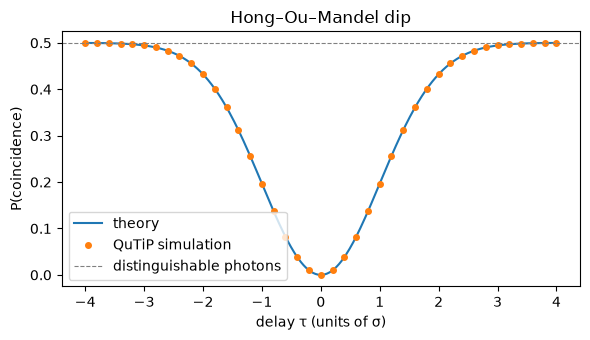

In [6]:
import matplotlib.pyplot as plt
taus = np.linspace(-4, 4, 41)
sim = [coinc(np.arccos(np.exp(-t**2 / 4))) for t in taus]
fine = np.linspace(-4, 4, 400)
plt.figure(figsize=(6, 3.5))
plt.plot(fine, 0.5 * (1 - np.exp(-fine**2 / 2)), label="theory")
plt.plot(taus, sim, "o", ms=4, label="QuTiP simulation")
plt.axhline(0.5, ls="--", lw=0.8, color="gray", label="distinguishable photons")
plt.xlabel("delay τ (units of σ)"); plt.ylabel("P(coincidence)"); plt.title("Hong–Ou–Mandel dip")
plt.legend(); plt.tight_layout(); plt.show()

## Validation summary

Every `check` above compared a QuTiP result with its analytic formula.

In [7]:
print(f"{sum(results)} of {len(results)} checks passed")
assert all(results), "a simulation disagrees with theory"

14 of 14 checks passed
